# EDA từ CSV gốc — Phase 1
Chạy kernel sạch; không sửa nguồn, không in mã khách/từng giao dịch. Mỗi đoạn code có lời giải thích ngay dưới.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
import pandas as pd
base = Path.cwd().parent
sys.path.insert(0, str(base / 'scripts'))
from phase1 import analyze
p, a = analyze()
print({'source_sha256': p['sha256'], 'rows': p['summary']['rows'], 'columns': p['summary']['columns']})

{'source_sha256': '4c967c8bcbecebe44ff542bb4f3722630ab62e1cfa93264e1984ae998680fe4c', 'rows': 6073, 'columns': 27}


Đã đọc CSV gốc trực tiếp như mở một sổ đơn hàng. Có 6,073 dòng và 27 cột. Chỉ tính trong bộ nhớ, chưa sửa dữ liệu hoặc điền ô trống.

{'min': '2026-03-01', 'max': '2026-08-31', 'valid_n': 6073, 'distinct_days': 184, 'missing_days_within_observed_span': []}


,group,orders,cancel_n,cancel_denominator,cancel_pct,late_n,late_denominator,late_pct,late_coverage_of_completed_pct,delivery_n,delivery_mean,delivery_median
0,2026-03,920,32,920,3.478261,53,888,5.968468,100.0,888,27.443356,26.7
1,2026-04,886,24,886,2.708804,40,862,4.640371,100.0,862,27.500232,27.0
2,2026-05,1029,30,1029,2.915452,124,999,12.412412,100.0,999,30.129429,28.7
3,2026-06,1028,39,1028,3.793774,126,989,12.740142,100.0,989,30.273306,29.2
4,2026-07,1066,76,1066,7.129456,157,990,15.858586,100.0,990,30.911313,29.3
5,2026-08,1144,147,1144,12.849650,250,997,25.075226,100.0,997,34.397894,32.4


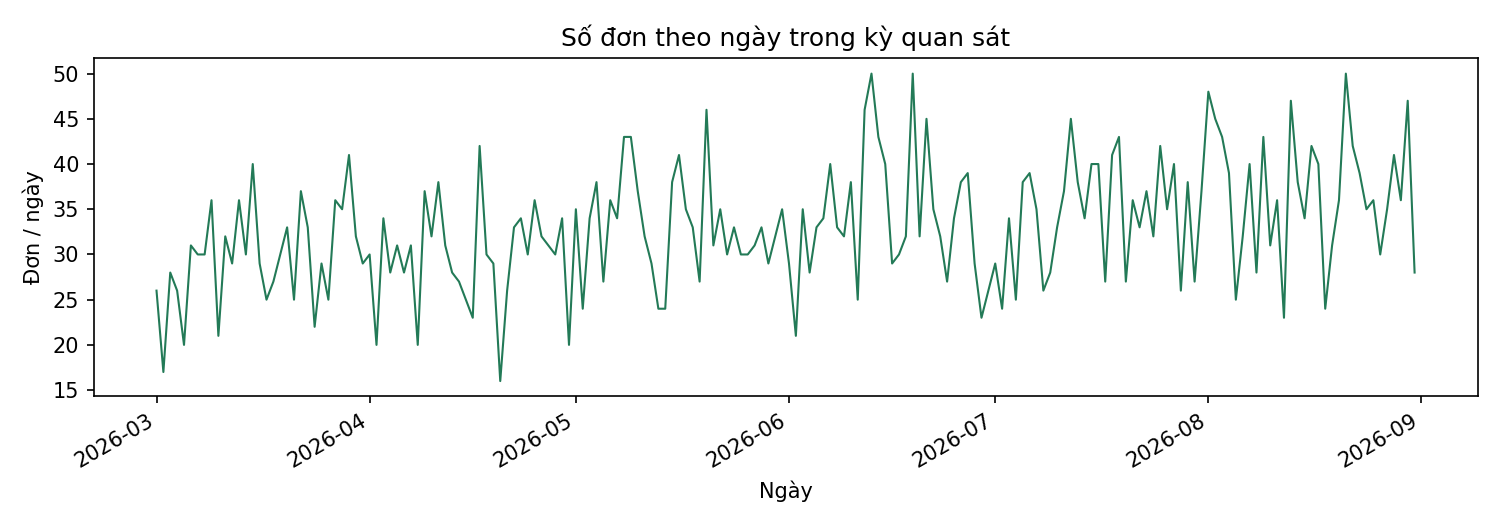

In [2]:
print(p['period'])
display(pd.DataFrame(a['groups']['month_observed']))
display(Image(filename=str(base/'reports/phase1/01_daily_orders.png')))

Mỗi dòng có một mã đơn riêng; ghi nhận 0 dòng trùng toàn bộ. Kỳ quan sát 2026-03-01 đến 2026-08-31, có 184 ngày có đơn và 0 ngày thiếu bên trong kỳ. Đây là kỳ thấy trong sổ, không phải ngày chụp hay toàn lịch sử kinh doanh.

In [3]:
print(p['summary'])
display(pd.DataFrame(p['cohort_missing']))
print(next(r['labels'] for r in p['columns'] if r['column']=='cancel_reason'))

{'rows': 6073, 'columns': 27, 'completed_by_project_rule': 5725, 'cancelled': 348, 'unknown_status': 0, 'cancel_denominator': 6073, 'late_numerator': 750, 'late_denominator': 5725, 'distinct_customers': 2098, 'customers_missing_rows': 0, 'duplicates': 0, 'duplicate_keys_different_content': 0, 'negative_profit_orders': 1320, 'merchant_multiple_cuisine_n': 0, 'cancel_pct': 5.7302815741808, 'late_pct': 13.100436681222707}


,cohort,n,prep_min_missing,rider_wait_min_missing,travel_min_missing,delivery_min_missing,is_late_missing,rating_missing,cancel_reason_missing
0,completed,5725,0,0,0,0,0,0,5725
1,cancelled,348,0,0,348,348,348,348,0
2,unknown,0,0,0,0,0,0,0,0


{'<missing>': 5725, 'Chờ tài xế quá lâu': 198, 'Khách đổi ý': 73, 'Nhà hàng hết món': 45, 'Sai địa chỉ': 32}


Có 348/6,073 đơn mang cờ hủy (5.73%). Trễ là 750/5,725 đơn đủ thông tin vận hành (13.10%). 5,725 đơn cờ 0 được gọi là hoàn thành theo quy tắc dự án; các ô trống của đơn hủy vẫn giữ trống. Cờ trễ chưa cho biết ngưỡng cam kết giao hàng.

,metric,n,denominator,missing,coverage_pct,sum,mean,median
0,prep_min,5725,5725,0,100.0,65643.5,11.466114,11.1
1,rider_wait_min,5725,5725,0,100.0,35308.7,6.167459,4.6
2,travel_min,5725,5725,0,100.0,72063.8,12.587563,11.6
3,delivery_min,5725,5725,0,100.0,173011.4,30.220332,28.8


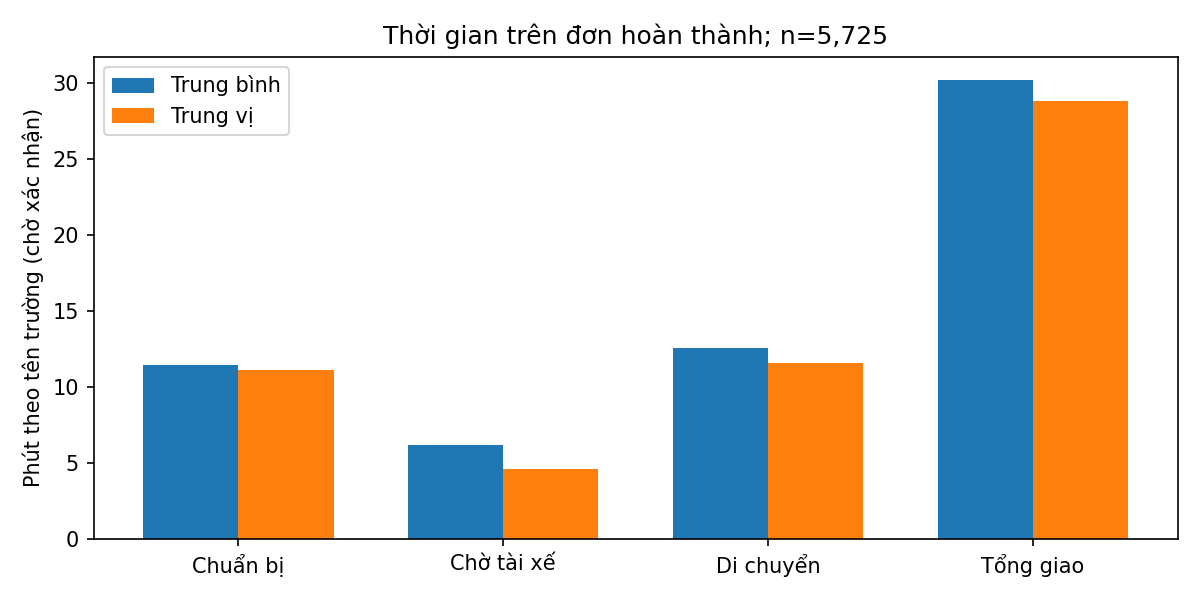

In [4]:
display(pd.DataFrame(a['timing_completed']))
display(Image(filename=str(base/'reports/phase1/03_time_steps.png')))

Bảng thời gian chỉ dùng đơn cờ hủy bằng 0 có thời gian không âm và hữu hạn; n là số đơn dùng được. prep_min: trung bình 11.47, trung vị 11.10, n=5,725; rider_wait_min: trung bình 6.17, trung vị 4.60, n=5,725; travel_min: trung bình 12.59, trung vị 11.60, n=5,725; delivery_min: trung bình 30.22, trung vị 28.80, n=5,725. Trung bình giống chia đều tổng thời gian, trung vị là giá trị ở giữa. Chưa xác nhận các bước có chồng nhau không, nên thời gian dài hơn chưa tự xác định bên nào có lỗi.

In [5]:
display(pd.DataFrame(a['financial_by_cohort']).query("metric in ['order_value','revenue','profit']"))

,cohort,metric,n,denominator,missing,coverage_pct,sum,mean,median
0,completed,order_value,5725,5725,0,100.0,475555000.0,83066.375546,65000.0
6,completed,revenue,5725,5725,0,100.0,203341200.0,35518.113537,32800.0
7,completed,profit,5725,5725,0,100.0,58083200.0,10145.537118,8000.0
8,cancelled,order_value,348,348,0,100.0,27426000.0,78810.344828,61000.0
14,cancelled,revenue,348,348,0,100.0,0.0,0.000000,0.0
15,cancelled,profit,348,348,0,100.0,-7224000.0,-20758.620690,-18000.0
16,unknown,order_value,0,0,0,NaN,NaN,NaN,NaN
22,unknown,revenue,0,0,0,NaN,NaN,NaN,NaN
23,unknown,profit,0,0,0,NaN,NaN,NaN,NaN


order_value là giá trị đơn được ghi (reported GMV), khác revenue là thu nhập nền tảng theo công thức dự án; profit trừ rider_pay và compensation. Đơn hủy vẫn có thể mang order_value và chi phí. Có 1,320/6,073 đơn profit âm; đây là chênh lệch cần phân tích, chưa là lỗi để xóa. Các tổng dưới đây giữ đơn vị số gốc; chưa được gọi là VND hoặc lợi nhuận kế toán đầy đủ.

zone


,group,orders,cancel_n,cancel_denominator,cancel_pct,late_n,late_denominator,late_pct,late_coverage_of_completed_pct,delivery_n,delivery_mean,delivery_median
0,Bình Thạnh,940,55,940,5.851064,108,885,12.203390,100.0,885,30.172994,28.60
1,Gò Vấp,657,42,657,6.392694,91,615,14.796748,100.0,615,30.556423,29.00
2,Phú Nhuận,622,37,622,5.948553,82,585,14.017094,100.0,585,30.607350,29.60
3,Quận 1,963,63,963,6.542056,114,900,12.666667,100.0,900,30.065444,28.45
4,Quận 3,791,50,791,6.321113,92,741,12.415655,100.0,741,30.292982,28.60
5,Quận 7,725,46,725,6.344828,87,679,12.812960,100.0,679,29.699411,28.30
6,Thủ Đức,666,27,666,4.054054,86,639,13.458529,100.0,639,29.970110,28.60
7,Tân Bình,709,28,709,3.949224,90,681,13.215859,100.0,681,30.525698,29.30


time_slot


,group,orders,cancel_n,cancel_denominator,cancel_pct,late_n,late_denominator,late_pct,late_coverage_of_completed_pct,delivery_n,delivery_mean,delivery_median
0,Chiều,709,29,709,4.090268,40,680,5.882353,100.0,680,26.537794,25.4
1,Khuya,496,12,496,2.419355,24,484,4.958678,100.0,484,26.595248,25.5
2,Sáng,646,22,646,3.405573,38,624,6.089744,100.0,624,26.889583,25.6
3,Trưa,2087,87,2087,4.168663,257,2000,12.850000,100.0,2000,30.959100,29.9
4,Tối,2135,198,2135,9.274005,391,1937,20.185854,100.0,1937,32.729117,31.2


is_rain


,group,orders,cancel_n,cancel_denominator,cancel_pct,late_n,late_denominator,late_pct,late_coverage_of_completed_pct,delivery_n,delivery_mean,delivery_median
0,0.0,3884,160,3884,4.119464,281,3724,7.545650,100.0,3724,28.053276,27.1
1,1.0,2189,188,2189,8.588397,469,2001,23.438281,100.0,2001,34.253373,33.0


distance_band


,group,orders,cancel_n,cancel_denominator,cancel_pct,late_n,late_denominator,late_pct,late_coverage_of_completed_pct,delivery_n,delivery_mean,delivery_median
0,2–4 km,3093,183,3093,5.916586,241,2910,8.281787,100.0,2910,28.973299,27.7
1,4–6 km,1217,73,1217,5.998357,206,1144,18.006993,100.0,1144,34.159790,33.0
2,<2 km,1300,68,1300,5.230769,53,1232,4.301948,100.0,1232,25.118344,23.9
3,>6 km,463,24,463,5.183585,250,439,56.947608,100.0,439,42.538724,41.3


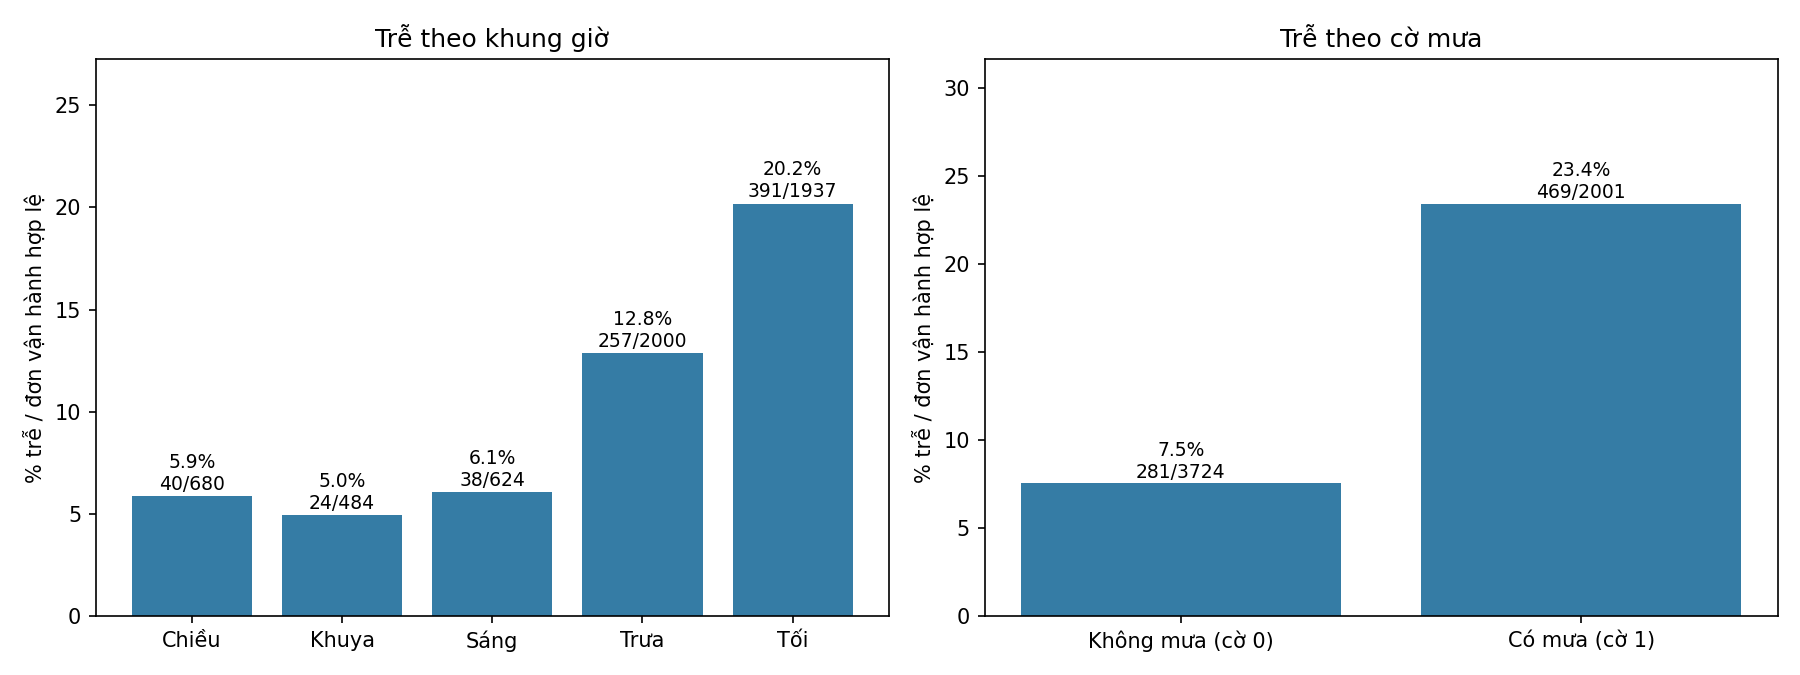

Điểm biên khoảng cách:


,distance_km,distance_band,n
0,2.0,2–4 km,181
1,4.0,4–6 km,98
2,6.0,>6 km,32


In [6]:
for dimension in ['zone','time_slot','is_rain','distance_band']:
    print(dimension)
    display(pd.DataFrame(a['groups'][dimension]))
display(Image(filename=str(base/'reports/phase1/02_late_groups.png')))
print('Điểm biên khoảng cách:')
display(pd.DataFrame(p['distance_boundary_counts']))

So nhóm như so các trang trong cùng sổ: tỷ lệ hủy chia cho đơn có cờ hợp lệ, tỷ lệ trễ chia cho đơn hoàn thành đủ thông tin. Bảng ghi cả tử số, mẫu số và độ phủ để nhóm ít đơn không bị nhìn ngang nhóm lớn. Nhãn khu vực/giờ/mưa/khoảng cách giữ nguyên như nguồn; chênh lệch là quan sát, chưa chứng minh mưa hay khoảng cách gây trễ.

In [7]:
print(a['customer_summary'])
display(pd.DataFrame(a['groups']['customer_type']))
display(pd.DataFrame(a['customer_frequency']))

{'customers': 2098, 'with_2plus_orders': 1261, 'repeat_customer_pct': 60.10486177311726, 'orders_per_customer_mean': 2.8946615824594852, 'orders_per_customer_median': 2.0, 'order_rows_covered': 6073, 'denominator_rows': 6073, 'label_conflicting_customers': 252}


,group,orders,cancel_n,cancel_denominator,cancel_pct,late_n,late_denominator,late_pct,late_coverage_of_completed_pct,delivery_n,delivery_mean,delivery_median
0,Mới,551,31,551,5.626134,74,520,14.230769,100.0,520,30.548269,28.6
1,Quay lại,5522,317,5522,5.740674,676,5205,12.987512,100.0,5205,30.187570,28.8


,orders_in_observed_period,customers
0,1,837
1,2,538
2,3,312
3,4,166
4,5,74
5,6,52
6,7,24
7,8,20
8,9,12
9,10,10


Có 2,098 mã khách; 1,261/2,098 khách có từ hai đơn trong kỳ (60.10%). Mỗi khách trung bình 2.89 đơn, trung vị 2 đơn. Nhãn Quay lại/Mới được đếm theo dòng đơn, khác việc tự đếm khách mua lặp lại. Không có lịch sử ngoài kỳ để đo giữ chân hoặc rời bỏ.

In [8]:
display(pd.DataFrame(p['residuals']))
check_status = pd.DataFrame(p['checks'])
print(check_status['status'].value_counts().to_dict())
display(check_status[check_status['status'] != 'PASS'])
assert all(c['null']+c['non_null']==p['summary']['rows'] for c in p['columns'])
print('Null + non-null khớp ở mọi cột. Câu hỏi nghiệp vụ còn pending:', p['semantics']['pending'])

,formula,basis,n,denominator,missing,tolerance,reason,violations,max_abs,mean_residual
0,revenue = commission + delivery_fee - discount,legacy project hypothesis,6073,6073,0,1.000000e-08,All source money cells are integer-valued; tol...,0,0.0,0.000000
1,profit = revenue - rider_pay - compensation,legacy project hypothesis,6073,6073,0,1.000000e-08,All source money cells are integer-valued; no ...,0,0.0,0.000000
2,delivery_min = prep_min + rider_wait_min + tra...,legacy project hypothesis,5725,6073,348,2.000000e-01,Source time precision 0.1; rounding four terms...,0,0.1,-0.000803


{'PASS': 112, 'FAIL': 1}


,check,expected,actual,status,basis
106,distance label >6 km: membership,0,32,FAIL,source label literal greater than; legacy scri...


Null + non-null khớp ở mọi cột. Câu hỏi nghiệp vụ còn pending: ['Currency and scaling', 'GMV includes cancelled order_value?', 'Revenue/profit recognized accounting scope, refunds/taxes/overhead', 'Late SLA and label generation', 'Time step overlap and unit confirmation', 'Distance endpoints and slot boundaries', 'customer_type definition and history outside observed span']


Sai số dư (residual) là phần còn lệch khi ghép các khoản như cộng các dòng trong sổ. Công thức tài chính dùng dung sai 0.00000001 đơn vị số gốc; thời gian dùng 0.2 phút cộng sai số máy vì bốn số được làm tròn 0.1. Đây là dung sai kiểm tra, không là ngưỡng giao trễ. PASS chỉ nói số khớp công thức dự án, chưa xác nhận định nghĩa kế toán hay SLA.